# Machine Learning: Exercise 2

## Clustering with k-means

In [ ]:
%pip install scikit-learn==1.4.2
%pip install matplotlib==3.8.4
%pip install numpy==1.26.4

### Task 1
Generate a 2D synthetic dataset with three clusters.

In [2]:
from sklearn.datasets import make_blobs

X, _ = make_blobs(n_samples=300, centers=3, cluster_std=0.8, random_state=42)

### Task 2
Apply the k-means algorithm with k = 3.

In [3]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42)
labels = kmeans.fit_predict(X)

### Task 3
Visualize the clustering result:
-	Color data points according to their cluster
-	Mark cluster centers clearly
-	Add a legend for clusters

Use the following color convention:
-	Cluster 0: red
-	Cluster 1: green
-	Cluster 2: blue

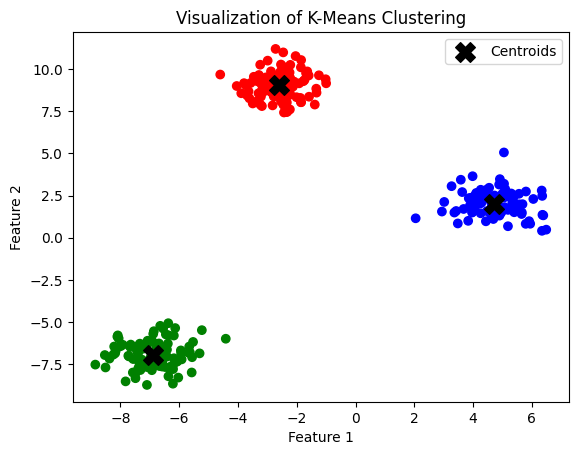

In [4]:
import matplotlib.pyplot as plt

# Take the cluster centers
centers = kmeans.cluster_centers_
# Clusters colors are determined by the labels assigned to each point

# Cluster 0: red
# Cluster 1: green
# Cluster 2: blue
color_map = {0: 'red', 1: 'green', 2: 'blue'}
colors = [color_map[label] for label in labels]
plt.scatter(X[:, 0], X[:, 1], c=colors)


# Plot the cluster centers
plt.scatter(centers[:, 0], centers[:, 1], marker='X', s=200, c='black', label='Centroids')

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Visualization of K-Means Clustering")
plt.legend()
plt.show()

## Predicting Clusters for New Data

### Task 4
Generate 5 new random data points.

In [5]:
import numpy as np

np.random.seed(1)

X_new = np.random.uniform(low=X.min(axis=0), high=X.max(axis=0), size=(5, 2))

### Task 5
Predict the cluster label for each new point using the trained k-means model.

In [6]:
# Genenerate 5 new random data points within the range of the original dataset
np.random.seed(1)
X_new = np.random.uniform(
    low=X.min(axis=0),
    high=X.max(axis=0),
    size=(5, 2)
)

# Predict the cluster labels for the new data points
new_labels = kmeans.predict(X_new)

print("The 5 new data points and their predicted cluster labels:")
for i, (point, label) in enumerate(zip(X_new, new_labels)):
    print(f"Point {i+1}: {point}  -->  Cluster {label}")

The 5 new data points and their predicted cluster labels:
Point 1: [-2.45626033  5.62150376]  -->  Cluster 0
Point 2: [-8.8551873  -2.70157978]  -->  Cluster 1
Point 3: [-6.60445289 -6.88299415]  -->  Cluster 1
Point 4: [-5.99811891 -1.84081783]  -->  Cluster 1
Point 5: [-2.76713798  2.00730891]  -->  Cluster 0


### Task 6
Visualize:
-	Original clustered data
-	New data points using star markers
-	Colors of new points must match the predicted cluster colors

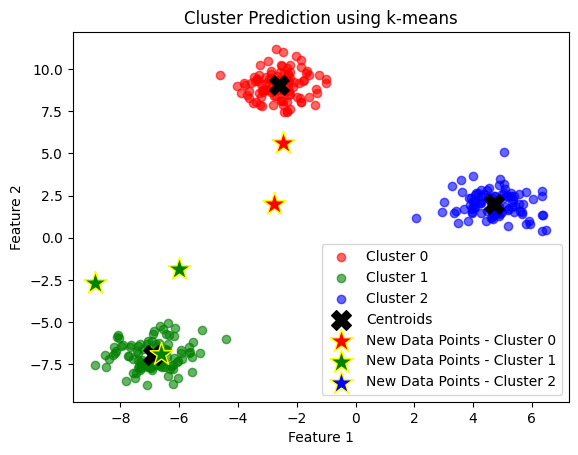

In [8]:
# Define colors for each cluster
cluster_colors = {
    0: 'red',
    1: 'green',
    2: 'blue'
}

# Draw the original clusters with their colors
for i in range(3):
    plt.scatter(
        X[labels == i, 0],
        X[labels == i, 1],
        c=cluster_colors[i],
        label=f"Cluster {i}",
        alpha=0.6
    )

# Draw the cluster centers
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c='black',
    marker='X',
    s=200,
    label='Centroids'
)

# Draw the new data points with their predicted cluster colors
for i in range(3):
    plt.scatter(
        X_new[new_labels == i, 0],
        X_new[new_labels == i, 1],
        c=cluster_colors[i],
        marker='*',
        s=300,
        edgecolors='yellow',
        label=f'New Data Points - Cluster {i}'
    )

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Cluster Prediction using k-means")
plt.legend()
plt.show()

## Reflection Questions

1. How does kNN decide the class label of a test sample?

In KNN, the class label is decided by computing the distance between the test sample and all training samples, then selecting the k nearest neighbors. The majority class among these neighbors is assigned as the predicted class label for the test sample.

2. Why is feature scaling important for distance-based algorithms?

Feature scaling is important for distance-based algorithms because it ensures that all features contribute equally to the distance calculations. If features are on different scales, the algorithm may give more weight to those with larger ranges, leading to biased results. Scaling helps to normalize the data, improving the performance of the algorithm.

3. What is the role of PCA in data visualization?

PCA (Principal Component Analysis) is a dimensionality reduction technique that transforms high-dimensional data into a lower-dimensional space while preserving as much variance as possible. In data visualization, PCA helps to reduce the number of features to 2 or 3, making it easier to visualize complex datasets and identify patterns or clusters.

4. How does k-means assign a data point to a cluster?

K-means assigns a data point to a cluster by calculating the distance between the data point and the centroids of each cluster. The data point is assigned to the cluster whose centroid is closest to it. After all points are assigned, the centroids are updated based on the mean of the assigned points, and the process is repeated until convergence.    

5. What are the limitations of k-means clustering?

- K-means assumes that clusters are spherical and equally sized, which may not always be the case in real-world data.
- It is sensitive to outliers, which can significantly affect the position of the centroids and lead to poor clustering results.
- The algorithm requires the number of clusters (k) to be specified in advance, which can be challenging to determine without prior knowledge of the data (Elbow Method and Silhouette Analysis are commonly used as techniques for determining the optimal number of clusters).
- K-means can converge to local minima, resulting in suboptimal clustering depending on the initial placement of centroids.

6. What is the functionality of the StandardScaler class?

This is a class from the sklearn.preprocessing module that standardizes features by removing the mean and scaling to unit variance. It transforms the data such that each feature has a mean of 0 and a standard deviation of 1, which is essential for many machine learning algorithms to perform well, especially those that rely on distance calculations.